In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import fdrcorrection
import seaborn as sns
import matplotlib.pyplot as plt

In [55]:
import itertools
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

In [56]:
WithoutDA = np.array([.58,.56,.67,.65,.63,.61])
Combat = np.array([.65,.61,.70,.71,.66,.65])
Can = np.array([.68,.63, .75,.73,.68,.67])
kPCA_DA=np.array([.70,.66,.77,.75,.70,.68])

In [57]:
names = ['WithoutDA', 'Combat', 'Can', 'kPCA_DA']
models = [WithoutDA, Combat, Can, kPCA_DA]

In [58]:
# Step 1: Pairwise Wilcoxon tests
pairs = list(itertools.combinations(range(len(models)), 2))
pvals = []
labels = []
for i, j in pairs:
    stat, p = wilcoxon(models[i], models[j])
    pvals.append(p)
    labels.append(f"{names[i]} vs {names[j]}")

In [60]:
# Step 2: FDR correction
reject, pvals_corrected, _, _ = multipletests(pvals, alpha=0.05, method='fdr_bh')

# Step 3: Create DataFrame
results_df = pd.DataFrame({
    "Comparison": labels,
    "Wilcoxon p-value": pvals,
    "FDR-corrected p-value": pvals_corrected,
    "Significant (FDR 0.05)": reject
})

# Step 4: Round for presentation
results_df = results_df.round(4)

print(results_df)


             Comparison  Wilcoxon p-value  FDR-corrected p-value  \
0   WithoutDA vs Combat            0.0312                 0.0312   
1      WithoutDA vs Can            0.0312                 0.0312   
2  WithoutDA vs kPCA_DA            0.0312                 0.0312   
3         Combat vs Can            0.0312                 0.0312   
4     Combat vs kPCA_DA            0.0312                 0.0312   
5        Can vs kPCA_DA            0.0312                 0.0312   

   Significant (FDR 0.05)  
0                    True  
1                    True  
2                    True  
3                    True  
4                    True  
5                    True  


In [ ]:
# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(p_df, annot=True, cmap='coolwarm', vmin=0, vmax=0.05,
            fmt='.4f', cbar_kws={'label': 'FDR-corrected p-value'})
plt.title('Pairwise Wilcoxon Signed-Rank Test (FDR-corrected)')
plt.tight_layout()

In [61]:
# Combine data into a matrix
data = np.vstack([WithoutDA, Combat, Can, kPCA_DA]).T
n_models = data.shape[1]

# Initialize p-value matrix
model_names = ['WithoutDA', 'Combat', 'Can', 'kPCA_DA']
p_matrix = np.ones((n_models, n_models))

In [62]:
# Perform pairwise Wilcoxon signed-rank tests
p_values = []
pairs = []
for i in range(n_models):
    for j in range(i + 1, n_models):
        stat, p = wilcoxon(data[:, i], data[:, j])
        p_values.append(p)
        pairs.append((i, j))
        print("p: ",p,"stat: ",stat)

p:  0.03125 stat:  0.0
p:  0.03125 stat:  0.0
p:  0.03125 stat:  0.0
p:  0.03125 stat:  0.0
p:  0.03125 stat:  0.0
p:  0.03125 stat:  0.0


In [63]:
p_values

[0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125]

In [64]:
# Apply FDR correction
rejected, p_values_fdr = fdrcorrection(p_values)

In [65]:
# Fill p-value matrix with FDR-corrected p-values
for idx, (i, j) in enumerate(pairs):
    p_matrix[i, j] = p_values_fdr[idx]
    p_matrix[j, i] = p_values_fdr[idx]

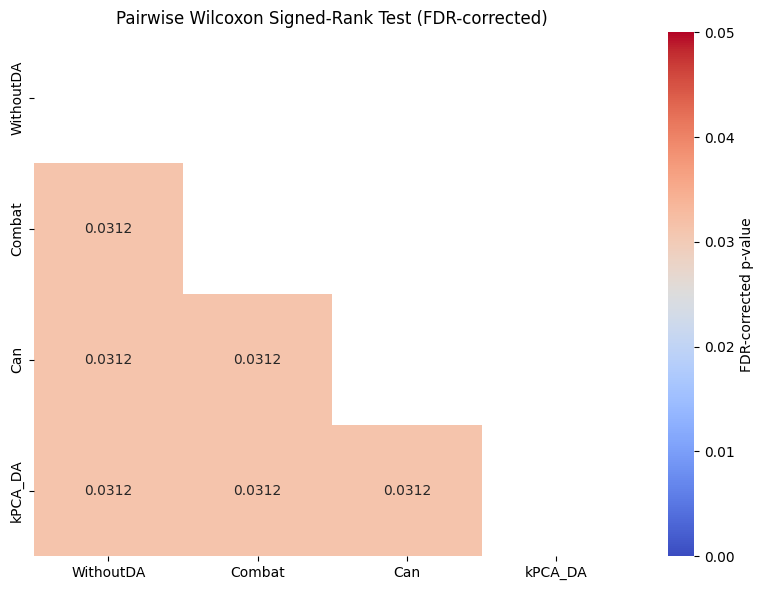

In [66]:
# Create mask for upper triangle and diagonal
mask = np.triu(np.ones_like(p_matrix, dtype=bool))

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(p_df, annot=True, cmap='coolwarm', vmin=0, vmax=0.05,
            fmt='.4f', cbar_kws={'label': 'FDR-corrected p-value'},
            mask=mask)
plt.title('Pairwise Wilcoxon Signed-Rank Test (FDR-corrected)')
plt.tight_layout()

# Save and show plot
plt.savefig('fdr_wilcoxon_heatmap.png')
plt.show()

In [67]:
# Save and show plot
plt.savefig('fdr_wilcoxon_heatmap.png')
plt.show()

<Figure size 640x480 with 0 Axes>